In [1]:
#Topic: Exoplanet Properties in Research Papers
#To investigate whether exoplanets that receive more attention in scientific research also receive more attention from the general public, 
#we can analyze data from research papers and public interest metrics.



In [ ]:
%pip install arxiv pandas matplotlib scipy

import pandas as pd
import matplotlib.pyplot as plt
import arxiv
import re
from pathlib import Path



Note: you may need to restart the kernel to use updated packages.


In [ ]:
import arxiv
import pandas as pd

search = arxiv.Search(
    query="cat:astro-ph.EP AND all:exoplanet",
    max_results=100,
    sort_by=arxiv.SortCriterion.SubmittedDate
)

client = arxiv.Client()

papers = []

for paper in client.results(search):
    papers.append({
        "title": paper.title,
        "abstract": paper.summary,
        "published": paper.published,
        "arxiv_id": paper.get_short_id()
    })

df = pd.DataFrame(papers)

print("Number of papers collected:", len(df))
df.head()

Number of papers collected: 100


,title,abstract,published,arxiv_id
0,The first selection of optimal targets for the...,Direct detection and characterization of exopl...,2026-10-22 13:51:21+00:00,2610.31286v1
1,Searching for substellar companion candidates ...,"In this work, we survey M-type stars within 15...",2026-10-22 09:45:06+00:00,2610.31006v1
2,Astrometric detection of rocky exoplanets from...,The detection of orbiting exoplanets by way of...,2026-10-22 06:31:47+00:00,2610.30806v1
3,Detection of Solar-like Oscillations and Granu...,Stellar oscillations and granulation are key p...,2026-10-22 01:54:33+00:00,2610.30594v1
4,The Pandora SmallSat: post-launch operations a...,The Pandora SmallSat is a NASA flight project ...,2026-10-21 19:31:51+00:00,2610.30372v1


In [ ]:
import re

properties = {
    "Mass": r"\bmass(?:es)?\b",
    "Radius": r"\b(?:radius|radii)\b",
    "Temperature": r"\btemperatur\w*\b",
    "Atmosphere": r"\batmospher\w*\b",
    "Orbit": r"\borbit\w*\b",
    "Composition": r"\bcomposit\w*\b",
    "Habitability": r"\bhabit\w*\b"
}

text = (
    df["title"].fillna("") + " " +
    df["abstract"].fillna("")
).str.lower()

counts = {}

for property_name, pattern in properties.items():
    counts[property_name] = text.str.contains(
        pattern, regex=True
    ).sum()

property_df = pd.DataFrame(
    counts.items(),
    columns=["Property", "Paper Count"]
).sort_values("Paper Count", ascending=False)

property_df

,Property,Paper Count
3,Atmosphere,57
4,Orbit,45
0,Mass,37
2,Temperature,23
5,Composition,18
1,Radius,17
6,Habitability,17


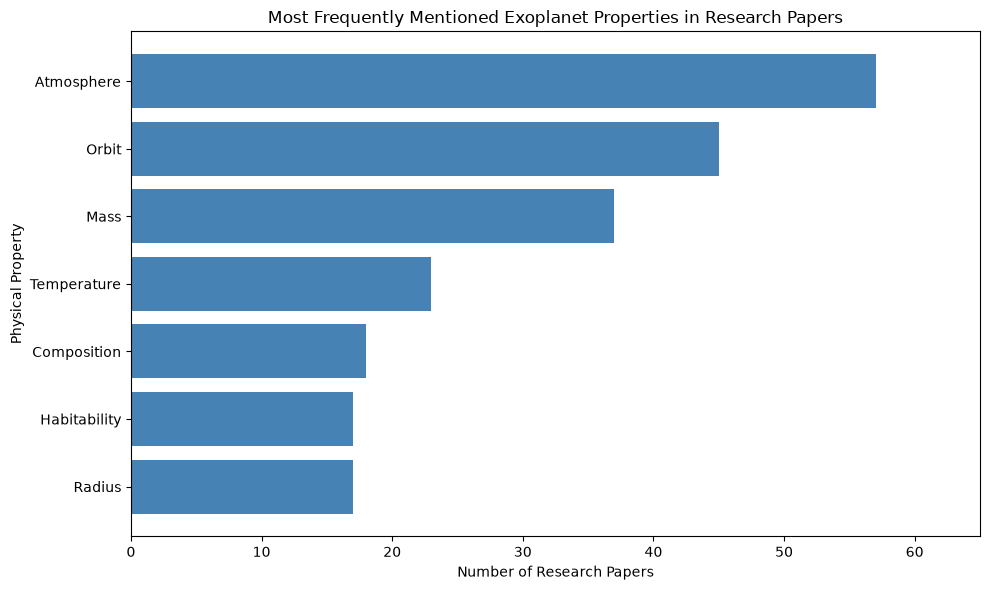

In [ ]:
import matplotlib.pyplot as plt

plot_df = property_df.sort_values("Paper Count")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Property"],
    plot_df["Paper Count"],
    color="steelblue"
)

plt.xlabel("Number of Research Papers")
plt.ylabel("Physical Property")
plt.title("Most Frequently Mentioned Exoplanet Properties in Research Papers")

plt.xlim(0, 65)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import ast
from pathlib import Path

# Load our team's existing Wikipedia data
file_path = Path("../physical_properties/exoplanet_views.csv")

if not file_path.exists():
    file_path = Path("physical_properties/exoplanet_views.csv")

views_df = pd.read_csv(file_path)

# Extract exoplanet names
views_df["planet_name"] = views_df["0"].apply(
    lambda x: ast.literal_eval(x)[0]
)

# Keep names and popularity
views_df = views_df[["planet_name", "view_count"]]

views_df.head(10)

,planet_name,view_count
0,Alpha Centauri Ab (?),71834.0
1,Beta Pictoris b,129344.0
2,51 Eridani b,37943.0
3,HR 8799 e,38382.0
4,HR 8799 d,20850.0
5,HR 8799 c,23753.0
6,HR 8799 b,34965.0
7,HIP 99770 b,17002.0
8,14 Herculis c,16364.0
9,HR 2562 B,8202.0


In [ ]:
import re

# Combine each paper's title and abstract
paper_text = (
    df["title"].fillna("") + " " +
    df["abstract"].fillna("")
)

# Count papers mentioning each exoplanet
def count_mentions(planet_name):
    name = re.sub(r"\s*\(\?\)$", "", str(planet_name)).strip()
    pattern = r"(?<!\w)" + re.escape(name).replace(r"\ ", r"\s+") + r"(?!\w)"

    return paper_text.str.contains(
        pattern, case=False, regex=True
    ).sum()

views_df["research_mentions"] = views_df["planet_name"].apply(count_mentions)

# Display planets with the most research mentions
views_df.sort_values(
    "research_mentions", ascending=False
).head(15)

,planet_name,view_count,research_mentions
1316,Mars,15589110.0,6
129,TOI-2431 b,6939.0,3
1314,Mercury,9857676.0,3
1309,Ceres,5390673.0,2
865,WASP-39b,90304.0,2
48,K2-3d,38641.0,1
330,WD 1856+534 b,1.0,1
1295,WASP-13b,9907.0,1
963,55 Cancri e,525514.0,1
47,K2-3c,10867.0,1


In [ ]:
# Objects in our solar system
solar_system = [
    "Sun", "Moon", "Mercury", "Venus", "Earth",
    "Mars", "Jupiter", "Saturn", "Uranus",
    "Neptune", "Pluto", "Ceres", "Eris",
    "Haumea", "Makemake"
]

# Remove solar-system objects
exoplanets_only = views_df[
    ~views_df["planet_name"].str.strip().str.lower().isin(
        [name.lower() for name in solar_system]
    )
].copy()

# Keep planets mentioned in at least one paper
matched_planets = exoplanets_only[
    exoplanets_only["research_mentions"] > 0
]

print("Total objects remaining:", len(exoplanets_only))
print("Objects with research mentions:", len(matched_planets))

matched_planets.sort_values(
    "research_mentions", ascending=False
).head(15)

Total objects remaining: 1345
Objects with research mentions: 16


,planet_name,view_count,research_mentions
129,TOI-2431 b,6939.0,3
865,WASP-39b,90304.0,2
12,Epsilon Indi Ab,59714.0,1
46,K2-3b,13627.0,1
47,K2-3c,10867.0,1
48,K2-3d,38641.0,1
323,TOI-561 b,14864.0,1
330,WD 1856+534 b,1.0,1
354,LHS 3844 b,50354.0,1
414,KELT-18b,8263.0,1


In [ ]:
print("Total exoplanets:", len(exoplanets_only))

print(
    "Exoplanets mentioned in research:",
    len(matched_planets)
)

print(
    "Exoplanets with zero research mentions:",
    (exoplanets_only["research_mentions"] == 0).sum()
)

print("Earliest paper:", df["published"].min())
print("Latest paper:", df["published"].max())

Total exoplanets: 1345
Exoplanets mentioned in research: 16
Exoplanets with zero research mentions: 1329
Earliest paper: 2026-09-14 18:52:57+00:00
Latest paper: 2026-10-22 13:51:21+00:00


In [ ]:
import arxiv
import pandas as pd

client = arxiv.Client(
    page_size=100,
    delay_seconds=3,
    num_retries=3
)

all_papers = []

for year in range(2020, 2027):

    end_date = (
        "202609302359" if year == 2026
        else f"{year}12312359"
    )

    search = arxiv.Search(
        query=(
            f"cat:astro-ph.EP AND all:exoplanet "
            f"AND submittedDate:[{year}01010000 TO {end_date}]"
        ),
        max_results=200,
        sort_by=arxiv.SortCriterion.SubmittedDate,
        sort_order=arxiv.SortOrder.Descending
    )

    for paper in client.results(search):
        all_papers.append({
            "title": paper.title,
            "abstract": paper.summary,
            "published": paper.published,
            "arxiv_id": paper.get_short_id(),
            "year": year
        })

    print(f"Completed {year}")

historical_df = pd.DataFrame(all_papers)

print("\nTotal papers:", len(historical_df))
print("\nPapers by year:")
print(historical_df.groupby("year").size())

Completed 2020
Completed 2021
Completed 2022
Completed 2023
Completed 2024
Completed 2025
Completed 2026

Total papers: 1400

Papers by year:
year
2020    200
2021    200
2022    200
2023    200
2024    200
2025    200
2026    200
dtype: int64


In [ ]:
# Remove duplicate papers, if any
historical_df = historical_df.drop_duplicates(
    subset="arxiv_id"
)

# Combine paper titles and abstracts
paper_text = (
    historical_df["title"].fillna("") + " " +
    historical_df["abstract"].fillna("")
)

# Recalculate mentions using our existing function
exoplanets_only["research_mentions"] = (
    exoplanets_only["planet_name"].apply(count_mentions)
)

# Keep exoplanets mentioned at least once
matched_planets = exoplanets_only[
    exoplanets_only["research_mentions"] > 0
].copy()

print("Total unique papers:", len(historical_df))
print("Total exoplanets:", len(exoplanets_only))
print("Exoplanets with research mentions:", len(matched_planets))
print("Exoplanets with zero mentions:",
      (exoplanets_only["research_mentions"] == 0).sum())

# Display the 15 most mentioned
matched_planets.sort_values(
    "research_mentions", ascending=False
).head(15)

Total unique papers: 1400
Total exoplanets: 1345
Exoplanets with research mentions: 133
Exoplanets with zero mentions: 1212


,planet_name,view_count,research_mentions
865,WASP-39b,90304.0,11
428,TRAPPIST-1e,661608.0,11
421,LHS 1140 b,249595.0,10
37,Proxima Centauri b,2914620.0,9
1294,WASP-12b,265465.0,8
541,WASP-121b,79508.0,7
49,K2-18b,2069578.0,7
413,KELT-9b,147370.0,7
1300,WASP-18b,39052.0,6
1299,WASP-17b,163048.0,6


Spearman correlation: 0.233
P-value: 5.684e-18


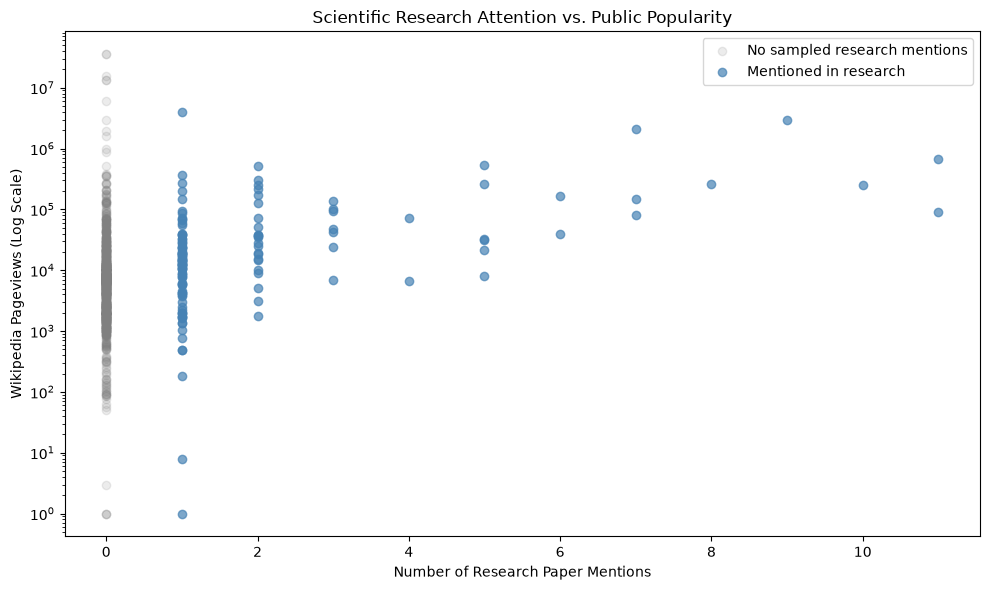

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import pandas as pd

# Prepare our data
correlation_df = exoplanets_only[
    ["planet_name", "view_count", "research_mentions"]
].copy()

correlation_df["view_count"] = pd.to_numeric(
    correlation_df["view_count"], errors="coerce"
)

correlation_df = correlation_df.dropna()
correlation_df = correlation_df[
    correlation_df["view_count"] > 0
]

# Calculate Spearman correlation
r, p = spearmanr(
    correlation_df["research_mentions"],
    correlation_df["view_count"]
)

print(f"Spearman correlation: {r:.3f}")
print(f"P-value: {p:.4g}")

# Separate planets by research mentions
zero = correlation_df[
    correlation_df["research_mentions"] == 0
]

matched = correlation_df[
    correlation_df["research_mentions"] > 0
]

# Create scatterplot
plt.figure(figsize=(10, 6))

plt.scatter(
    zero["research_mentions"],
    zero["view_count"],
    alpha=0.15,
    color="gray",
    label="No sampled research mentions"
)

plt.scatter(
    matched["research_mentions"],
    matched["view_count"],
    alpha=0.7,
    color="steelblue",
    label="Mentioned in research"
)

plt.yscale("log")

plt.xlabel("Number of Research Paper Mentions")
plt.ylabel("Wikipedia Pageviews (Log Scale)")
plt.title("Scientific Research Attention vs. Public Popularity")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr

r, p = spearmanr(
    correlation_df["research_mentions"],
    correlation_df["view_count"]
)

print(f"Spearman correlation: {r:.3f}")
print(f"P-value: {p:.4f}")

print("Total objects:", len(correlation_df))
print(
    "Objects with at least one research mention:",
    (correlation_df["research_mentions"] > 0).sum()
)

Spearman correlation: 0.233
P-value: 0.0000
Total objects: 1345
Objects with at least one research mention: 133


In [ ]:
from scipy.stats import spearmanr

# Only include objects with at least one research mention
researched_df = correlation_df[
    correlation_df["research_mentions"] > 0
].copy()

r, p = spearmanr(
    researched_df["research_mentions"],
    researched_df["view_count"]
)

print(f"Spearman correlation: {r:.3f}")
print(f"P-value: {p:.6f}")
print(f"Number of objects: {len(researched_df)}")

Spearman correlation: 0.493
P-value: 0.000000
Number of objects: 133


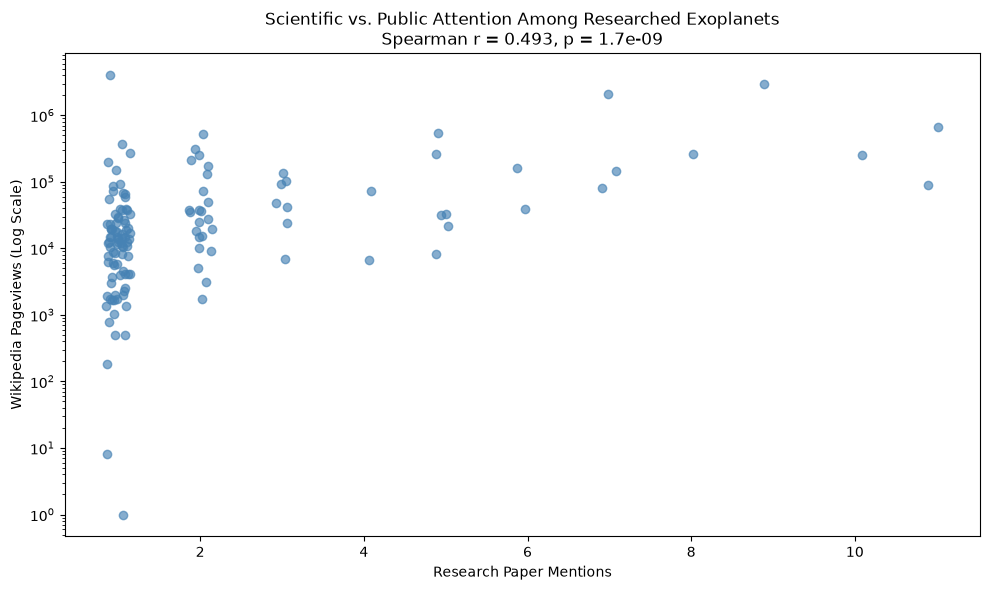

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

r, p = spearmanr(
    researched_df["research_mentions"],
    researched_df["view_count"]
)

# Add small horizontal jitter to reveal overlapping points
rng = np.random.default_rng(42)
x = researched_df["research_mentions"] + rng.uniform(
    -0.15, 0.15, len(researched_df)
)

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    researched_df["view_count"],
    color="steelblue",
    alpha=0.65
)

plt.yscale("log")
plt.xlabel("Research Paper Mentions")
plt.ylabel("Wikipedia Pageviews (Log Scale)")
plt.title(
    f"Scientific vs. Public Attention Among Researched Exoplanets\n"
    f"Spearman r = {r:.3f}, p = {p:.3g}"
)

plt.tight_layout()
plt.show()

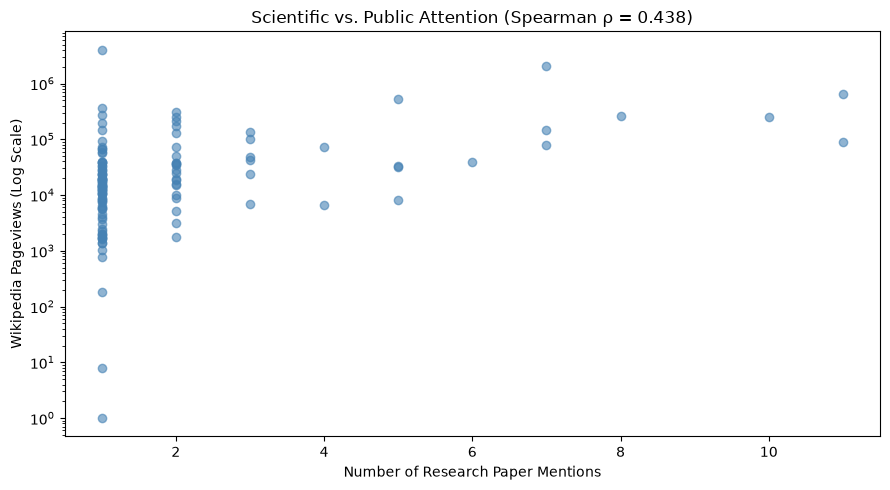

In [29]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plot_data = strict[strict["research_mentions"] > 0].copy()

r, p = spearmanr(
    plot_data["research_mentions"],
    plot_data["view_count"]
)

plt.figure(figsize=(9, 5))

plt.scatter(
    plot_data["research_mentions"],
    plot_data["view_count"],
    alpha=0.6,
    color="steelblue"
)

plt.yscale("log")
plt.xlabel("Number of Research Paper Mentions")
plt.ylabel("Wikipedia Pageviews (Log Scale)")
plt.title(f"Scientific vs. Public Attention (Spearman ρ = {r:.3f})")

plt.tight_layout()
plt.savefig("research_popularity_correlation.png", dpi=300)
plt.show()

In [ ]:
import re
import pandas as pd

# Combine titles and abstracts from all 1,400 papers
text = (
    historical_df["title"].fillna("") + " " +
    historical_df["abstract"].fillna("")
).str.lower()

# Physical properties to search for
properties = {
    "Mass": r"\bmass(?:es)?\b",
    "Radius": r"\b(?:radius|radii)\b",
    "Temperature": r"\btemperatur\w*\b",
    "Atmosphere": r"\batmospher\w*\b",
    "Orbit": r"\borbit\w*\b",
    "Composition": r"\bcomposit\w*\b",
    "Habitability": r"\bhabit\w*\b"
}

# Count how many papers mention each property
counts = {}

for property_name, pattern in properties.items():
    counts[property_name] = text.str.contains(
        pattern, regex=True
    ).sum()

property_df_1400 = pd.DataFrame(
    counts.items(),
    columns=["Property", "Paper Count"]
).sort_values("Paper Count", ascending=False)

property_df_1400["Percentage"] = (
    property_df_1400["Paper Count"] /
    len(historical_df) * 100
).round(1)

property_df_1400

,Property,Paper Count,Percentage
3,Atmosphere,717,51.2
4,Orbit,580,41.4
0,Mass,542,38.7
2,Temperature,294,21.0
1,Radius,275,19.6
5,Composition,256,18.3
6,Habitability,245,17.5


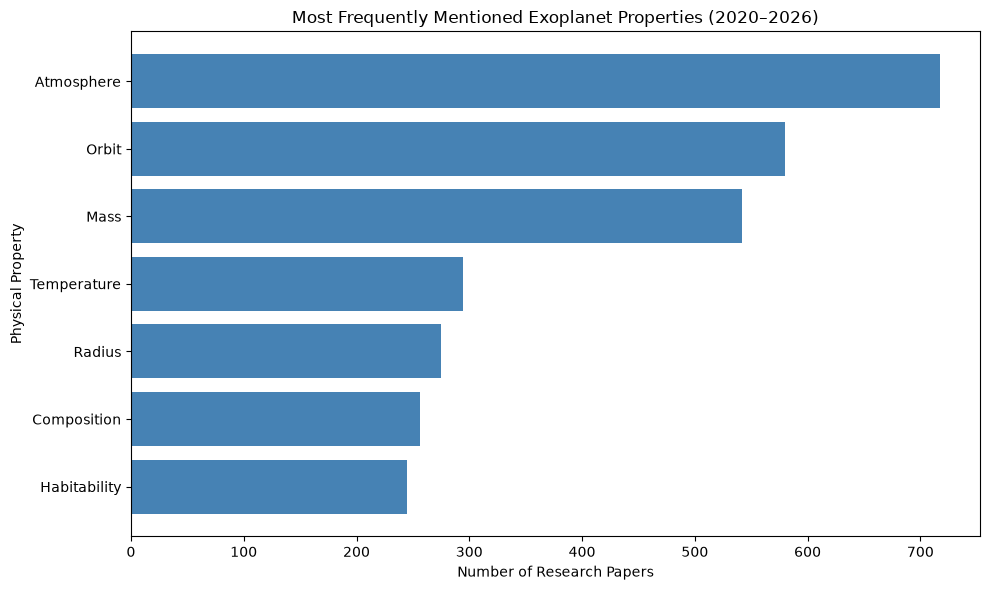

In [ ]:
import matplotlib.pyplot as plt

plot_df = property_df_1400.sort_values("Paper Count")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Property"],
    plot_df["Paper Count"],
    color="steelblue"
)

plt.xlabel("Number of Research Papers")
plt.ylabel("Physical Property")
plt.title("Most Frequently Mentioned Exoplanet Properties (2020–2026)")

plt.tight_layout()
plt.show()

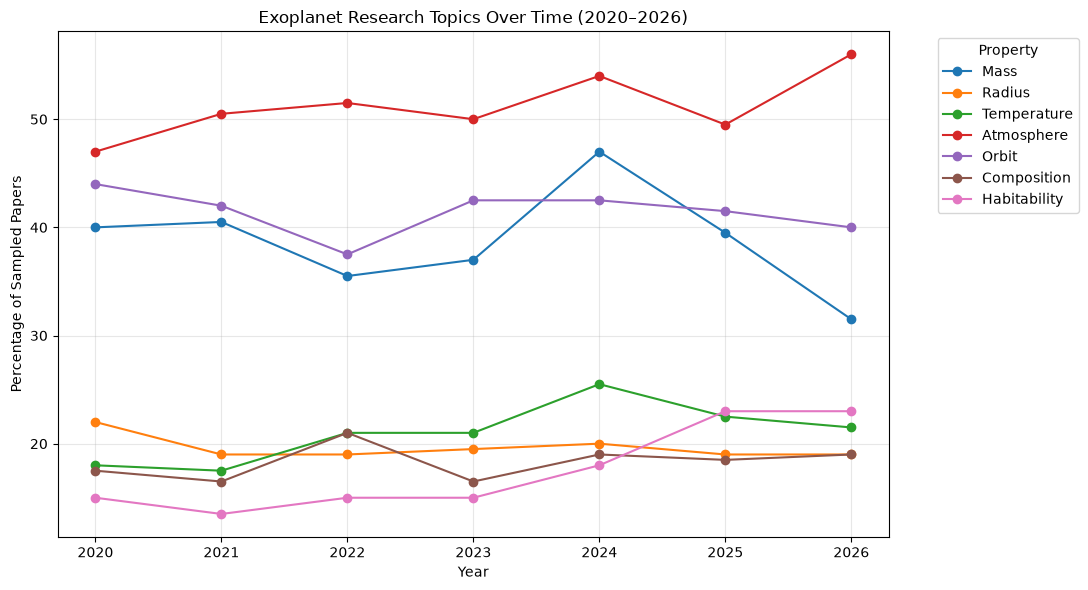

In [ ]:
# Calculate percentage of papers mentioning each property by year

yearly_data = historical_df.copy()

paper_text = (
    yearly_data["title"].fillna("") + " " +
    yearly_data["abstract"].fillna("")
).str.lower()

for name, pattern in properties.items():
    yearly_data[name] = paper_text.str.contains(
        pattern, regex=True
    )

yearly_percentages = (
    yearly_data.groupby("year")[list(properties.keys())]
    .mean() * 100
)

yearly_percentages.plot(
    figsize=(11, 6),
    marker="o"
)

plt.title("Exoplanet Research Topics Over Time (2020–2026)")
plt.xlabel("Year")
plt.ylabel("Percentage of Sampled Papers")
plt.legend(title="Property", bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
summary = yearly_percentages.loc[
    [2020, 2026]
].T.copy()

summary.columns = ["2020 (%)", "2026 (%)"]

summary["Change (percentage points)"] = (
    summary["2026 (%)"] - summary["2020 (%)"]
)

summary = summary.sort_values(
    "Change (percentage points)",
    ascending=False
)

print(summary.round(1))

              2020 (%)  2026 (%)  Change (percentage points)
Atmosphere        47.0      56.0                         9.0
Habitability      15.0      23.0                         8.0
Temperature       18.0      21.5                         3.5
Composition       17.5      19.0                         1.5
Radius            22.0      19.0                        -3.0
Orbit             44.0      40.0                        -4.0
Mass              40.0      31.5                        -8.5


In [ ]:
import ast
import pandas as pd
from scipy.stats import spearmanr

# Reload Wikipedia data, including article URLs
raw = pd.read_csv("../physical_properties/exoplanet_views.csv")

raw["planet_name"] = raw["0"].apply(
    lambda x: ast.literal_eval(x)[0]
)

raw["wiki_url"] = raw["0"].apply(
    lambda x: ast.literal_eval(x)[1]
)

# Attach research mentions already calculated
mentions = exoplanets_only.groupby(
    "planet_name"
)["research_mentions"].max()

raw["research_mentions"] = (
    raw["planet_name"].map(mentions).fillna(0)
)

# Remove solar-system objects, including reference entries
solar_pattern = (
    r"(?:Sun|Moon|Mercury|Venus|Earth|Mars|Jupiter|"
    r"Saturn|Uranus|Neptune|Pluto|Ceres|Eris|"
    r"Haumea|Makemake)(?:\s*\([^)]*\))?"
)

clean = raw[
    ~raw["planet_name"].str.fullmatch(
        solar_pattern, case=False
    )
].copy()

# For validation, keep only one-to-one article matches
strict = clean[
    ~clean["wiki_url"].duplicated(keep=False)
].copy()

strict = strict[
    ~strict["planet_name"].duplicated(keep=False)
]

# Compare correlations
for name, data in [
    ("Original filtered", clean),
    ("Unambiguous Wikipedia pages", strict)
]:
    data = data[data["view_count"] > 0]

    for group, subset in [
        ("All objects", data),
        ("Research-mentioned objects",
         data[data["research_mentions"] > 0])
    ]:
        if subset["research_mentions"].nunique() < 2:
            print(name, group, "Insufficient variation")
            continue

        r, p = spearmanr(
            subset["research_mentions"],
            subset["view_count"]
        )

        print(
            f"{name} | {group}: "
            f"n={len(subset)}, rho={r:.3f}, p={p:.4g}"
        )

Original filtered | All objects: n=1340, rho=0.236, p=2.009e-18
Original filtered | Research-mentioned objects: n=133, rho=0.493, p=1.703e-09
Unambiguous Wikipedia pages | All objects: n=1219, rho=0.246, p=3.178e-18
Unambiguous Wikipedia pages | Research-mentioned objects: n=119, rho=0.438, p=6.309e-07


In [ ]:
paper_check = historical_df.copy()

paper_check["published"] = pd.to_datetime(
    paper_check["published"], utc=True
)

print("Duplicate papers:",
      paper_check["arxiv_id"].duplicated().sum())

print(
    paper_check.groupby("year")["published"]
    .agg(["count", "min", "max"])
)

Duplicate papers: 0
      count                       min                       max
year                                                           
2020    200 2020-09-11 16:57:06+00:00 2020-12-31 19:13:53+00:00
2021    200 2021-09-14 23:13:00+00:00 2021-12-29 19:00:00+00:00
2022    200 2022-09-12 09:31:13+00:00 2022-12-31 21:23:49+00:00
2023    200 2023-09-21 02:03:05+00:00 2023-12-28 22:12:54+00:00
2024    200 2024-09-30 20:17:05+00:00 2024-12-30 19:02:29+00:00
2025    200 2025-10-16 13:54:13+00:00 2025-12-31 19:00:01+00:00
2026    200 2026-07-30 12:29:18+00:00 2026-09-30 23:15:05+00:00


In [ ]:
import arxiv
import pandas as pd
import calendar

client = arxiv.Client(
    page_size=25,
    delay_seconds=3,
    num_retries=3
)

records = []

for year in range(2020, 2027):
    for month in range(1, 10):

        last_day = calendar.monthrange(year, month)[1]

        start = f"{year}{month:02d}010000"
        end = f"{year}{month:02d}{last_day:02d}2359"

        search = arxiv.Search(
            query=(
                f"cat:astro-ph.EP AND all:exoplanet "
                f"AND submittedDate:[{start} TO {end}]"
            ),
            max_results=25,
            sort_by=arxiv.SortCriterion.SubmittedDate,
            sort_order=arxiv.SortOrder.Descending
        )

        for paper in client.results(search):
            records.append({
                "arxiv_id": paper.entry_id,
                "title": paper.title,
                "abstract": paper.summary,
                "published": paper.published,
                "year": year,
                "month": month
            })

balanced_df = pd.DataFrame(records)
balanced_df = balanced_df.drop_duplicates("arxiv_id")

print("Total papers:", len(balanced_df))
print(pd.crosstab(balanced_df["year"], balanced_df["month"]))

balanced_df.to_csv("arxiv_sample_by_month.csv", index=False)

Total papers: 1575
month   1   2   3   4   5   6   7   8   9
year                                     
2020   25  25  25  25  25  25  25  25  25
2021   25  25  25  25  25  25  25  25  25
2022   25  25  25  25  25  25  25  25  25
2023   25  25  25  25  25  25  25  25  25
2024   25  25  25  25  25  25  25  25  25
2025   25  25  25  25  25  25  25  25  25
2026   25  25  25  25  25  25  25  25  25
